# Calibrazione catena analogica
Volgiamo ottenere la curva di guadagno dell'insieme amplificatore ERZIA-LNA-2600-4000 in cavo, con una transizione in guida d'onda un filtro e in fine il diodo FTL-981B.
Non useremo il VNA per l'analisi dela risposta ma utilizziamo un gneratore di rafiofrequenze collegato alla nostra catena analogica con un connettore BNC, in uscita leggiamo solo l'ampiezza di risposta del sitema con un multimetro.
Il generatore RF ci permette di fare uno sweep in frequenza continuativamente, mentre possiamo ottenere tramite porta seriale una lettura continua della tensione in uscita dal diodo.
Il generatore lo usiamo in modalità 'sweep' impostando una $t_{sweep}$ di $90 s$, in cui scandagliamo una banda in frequenze compresa tra $[20;50]GHz$ impostando di campionare 1000 frequenze. 
Ogni $90 \text{milisecondi}$ si ha un campionamento diffrente in frequenza del generatore.
Il multimetro viene comandato da un programma scritto in python dal computer che ci permette di fare un'acquisizione continua, con un tempo di integrazione di $200 \text{ms}$, ogni misura del multimetro corrisponde a più frequenze campionate dal generatore, non disponendo di un sistema di trigger tra generatore e multimetro abbiamo deciso di mantenere un tempo di integrazione più alto di quello minimo legato ad ogni campione in frequenza proposto dal genratore in modo da minimizzare il rumore.
Inoltre attendiamo di osservare 5 sweep sulla banda in frequenza in modo da avere un minimo di statistica e poter fare una media da utilizzare come miglior stimatore della curva di guadagno.


Ora carichiamo le curve poniamo lo zero nel primo minimo assoluto compreso nei primi 90 secondi e poi facciamo la media facendo mille campionamenti su ogni curva.
Mostro il risulato in una unico grafico per differenti potenze in ingresso.

91.11323699951171
91.09514302015305
91.0938148021698
91.08509874343872
91.18678784370422
91.151258289814
91.09041798114777
91.15642800331116
91.13236083984376


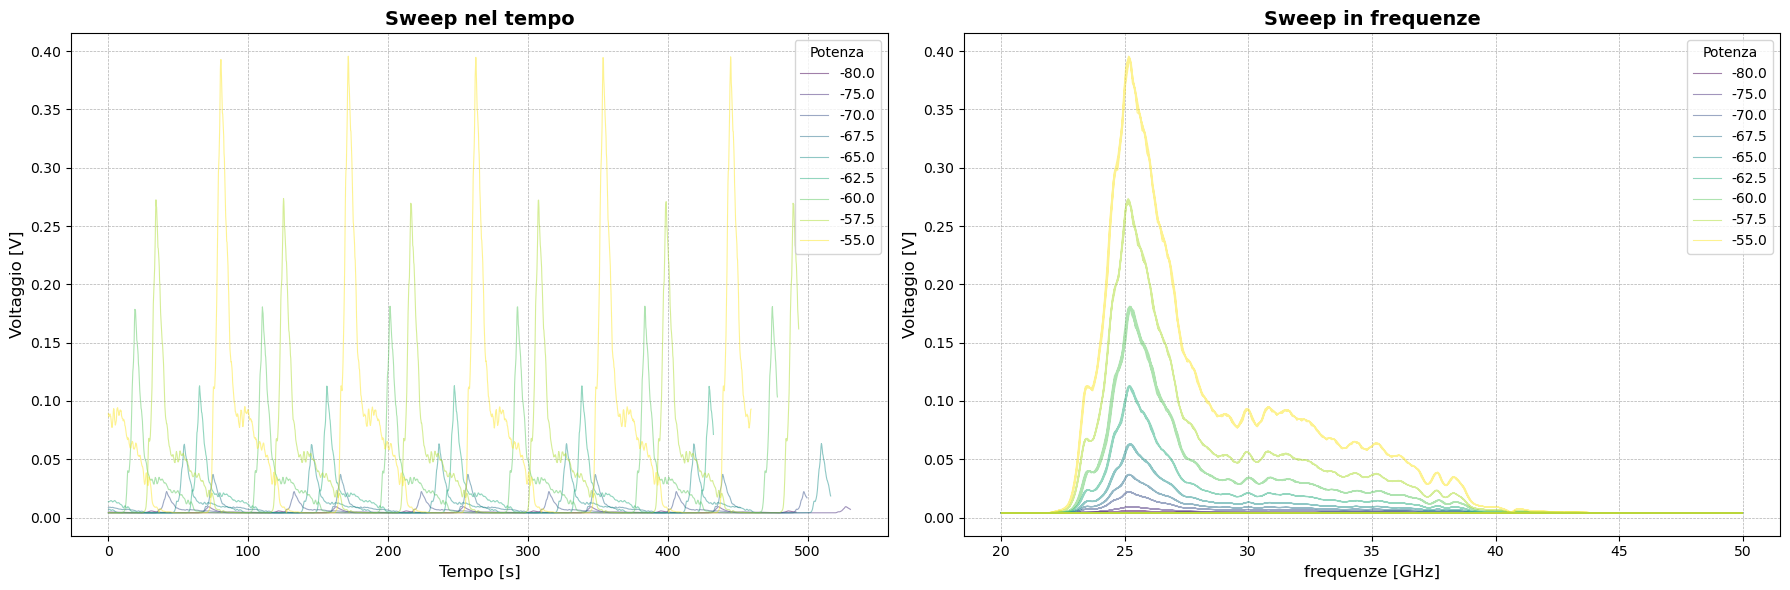

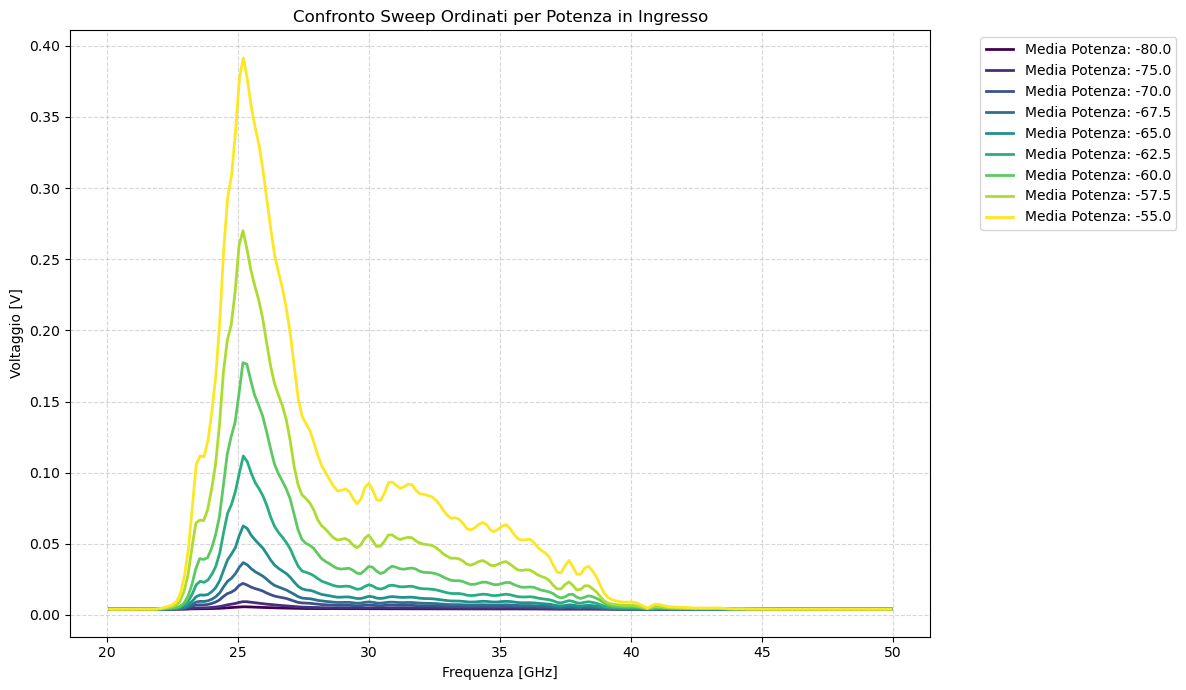

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import cm
from scipy.interpolate import interp1d,interpn

from scipy.signal import find_peaks
import numpy as np
import os
import re

# --- CONFIGURAZIONE ---
CARTELLA_DATI = 'dati'
FREQ_INIZIALE = 20.0  # GHz
FREQ_FINALE = 50.0    # GHz
FREQ_PICCO = 25.2     # GHz
DURATA_SWEEP = 91.1  # s
PEAKS = 5             #Max pick number
num_bins = 200

freqs = np.load('freqs.npy')

def estrai_valore_numerico(stringa_potenza):
    """
    Converte la stringa (es. '-10dBm') in un float per l'ordinamento.
    """
    match = re.search(r"[-+]?\d*\.\d+|\d+", stringa_potenza)
    return float(match.group()) if match else -999.0

def estrai_potenza(nome_file):
    match = re.search(r'prova_(.*?)_', nome_file)
    if match:
        return match.group(1)
    return "Sconosciuta"


def carica_e_raggruppa(cartella):
    serie_potenze = {}
    if not os.path.exists(cartella):
        print(f"Errore: La cartella {cartella} non esiste.")
        return serie_potenze

    files = [f for f in os.listdir(cartella) if f.startswith('prova_')]
    
    for nome_file in files:
        potenza_str = estrai_potenza(nome_file)
        percorso = os.path.join(cartella, nome_file)
        
       
        df = pd.read_csv(percorso, sep=r'\t+', header=None, usecols=[1, 2], 
                            names=['unix_time', 'voltaggio'], engine='python')
        df = df.apply(pd.to_numeric, errors='coerce').dropna()
        #inverting voltages and reset initial time to zero        
        df['voltaggio'] = -df['voltaggio']
        df['unix_time'] -= df['unix_time'][0]
         
        # 1. TROVA MASSIMO NEI PRIMI 90s (Assegnato a 25.2 GHz)
        # the sweep duration is not costant so i have to calculate 
        # it on the first 2 maximum and rescale the all time

        durata_sweep = 0.0
        revealed_peaks = 0

        for i in range(PEAKS):
    
            idx_max_1 = df[(df['unix_time'] <= DURATA_SWEEP*(i+1)) & (df['unix_time'] > DURATA_SWEEP*(i)) ]['voltaggio'].idxmax()
            t_max_1 = df.loc[idx_max_1, 'unix_time']
            idx_max_2 = df[(df['unix_time'] <= DURATA_SWEEP*(i+2)) & (df['unix_time'] > t_max_1) ]['voltaggio'].idxmax()
            t_max_2 = df.loc[idx_max_2, 'unix_time']

            if(abs((t_max_2-t_max_1)/DURATA_SWEEP-1) < 0.1):
                durata_sweep += t_max_2-t_max_1
                revealed_peaks += 1

        durata_sweep /= revealed_peaks

        print(durata_sweep)
    
        rate = (FREQ_FINALE - FREQ_INIZIALE) / durata_sweep

        df['frequenza'] = FREQ_INIZIALE + ((df['unix_time'] - t_max_1 + (FREQ_PICCO - FREQ_INIZIALE) / rate) % durata_sweep) * rate
        
        # Salviamo nel dizionario
        if potenza_str not in serie_potenze:
            serie_potenze[-float(potenza_str)] = []
        serie_potenze[-float(potenza_str)].append(df)
            
    return serie_potenze




def plot_dati_raw(serie_potenze):

    chiavi_ordinate = sorted(serie_potenze.keys(), key=lambda x: float(x))

    
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    
    # 2. Crea la colormap basata sul numero di chiavi ordinate
    colori = plt.cm.viridis(np.linspace(0, 1, len(chiavi_ordinate)))
    
    # 3. Itera sulle chiavi ordinate
    for i, potenza in enumerate(chiavi_ordinate):
        colore = colori[i]
        lista_df = serie_potenze[potenza]
        
        # Per evitare che la legenda sia infinita, usiamo un flag per la label
        # Solo il primo elemento di ogni gruppo di potenza apparirà nella legenda
        for j, df in enumerate(lista_df):
            label = str(potenza) if j == 0 else ""
            
            ax.plot(df['unix_time'], df['voltaggio'], color=colore, 
                    alpha=0.5, linewidth=0.8, label=label)
            ax2.plot(df['frequenza'], df['voltaggio'], color=colore, 
                    alpha=0.5, linewidth=0.8, label=label)
            
    # Impostazioni grafiche
    ax.set_title('Sweep nel tempo', fontsize=14, fontweight='bold')
    ax.set_xlabel('Tempo [s]', fontsize=12)
    ax.set_ylabel('Voltaggio [V]', fontsize=12)
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax.legend(title="Potenza", loc='best', fontsize=10)

    ax2.set_title('Sweep in frequenze', fontsize=14, fontweight='bold')
    ax2.set_xlabel('frequenze [GHz]', fontsize=12)
    ax2.set_ylabel('Voltaggio [V]', fontsize=12)
    ax2.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax2.legend(title="Potenza", loc='best', fontsize=10)

    plt.tight_layout()
    plt.show()


def plot_confronto(risultati):
    plt.figure(figsize=(12, 7))
    
    # --- LOGICA DI ORDINAMENTO ---
    # Creiamo una lista di tuple (chiave_str, valore_numerico)
    chiavi_ordinate = sorted(risultati.keys())
    
    # Colormap proporzionale al numero di serie ordinate
    colori = plt.cm.viridis(np.linspace(0, 1, len(chiavi_ordinate)))

    for potenza_str, col in zip(chiavi_ordinate, colori):
        f, m = risultati[potenza_str]
        plt.plot(f, m, label=f"Media Potenza: {potenza_str}", linewidth=2, color=col)

    plt.title("Confronto Sweep Ordinati per Potenza in Ingresso")
    #plt.xscale("log")
    #plt.yscale("log")
    plt.xlabel("Frequenza [GHz]")
    plt.ylabel("Voltaggio [V]")
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Legenda esterna per chiarezza
    plt.tight_layout()
    plt.show()


def calcola_media_serie(lista_df, num_bins=500):
    # Uniamo tutti i dataframe della lista in uno solo
    data = pd.concat(lista_df, ignore_index=True)
    
    # Ora 'data' è un DataFrame, non una lista
    freq_min = data['frequenza'].min()
    freq_max = data['frequenza'].max()

    bins = np.linspace(freq_min, freq_max, num_bins + 1)
    centri_bins = (bins[:-1] + bins[1:]) / 2

    #centri_bins = freqs
    #passo = freqs[1] - freqs[0]
    #bins = np.append(freqs - passo/2, freqs[-1] + passo/2)

    # ATTENZIONE: l'errore era anche qui: si usa pd.cut, non data.cut
    data['bin_index'] = pd.cut(data['frequenza'], bins=bins, labels=False, include_lowest=True)
    data['centro_bin'] = pd.cut(data['frequenza'], bins=bins, labels=centri_bins, include_lowest=True)

    # Calcola la media per centro_bin
    media_per_bin = data.groupby('centro_bin',observed=False)['voltaggio'].mean()

    # Ritorna i centri e le medie come array
    return media_per_bin.index.to_numpy(), media_per_bin.to_numpy()


# --- MAIN ---
if __name__ == "__main__":
    dati_per_potenza = carica_e_raggruppa(CARTELLA_DATI)

    plot_dati_raw(dati_per_potenza)
    
    risultati_finali = {}
    for potenza, lista_df in dati_per_potenza.items():
        f, media = calcola_media_serie(lista_df,num_bins) 
        risultati_finali[potenza] = (f, media)
    
    
    plot_confronto(risultati_finali)


Funzione di debug per poter osservare la singola potenza

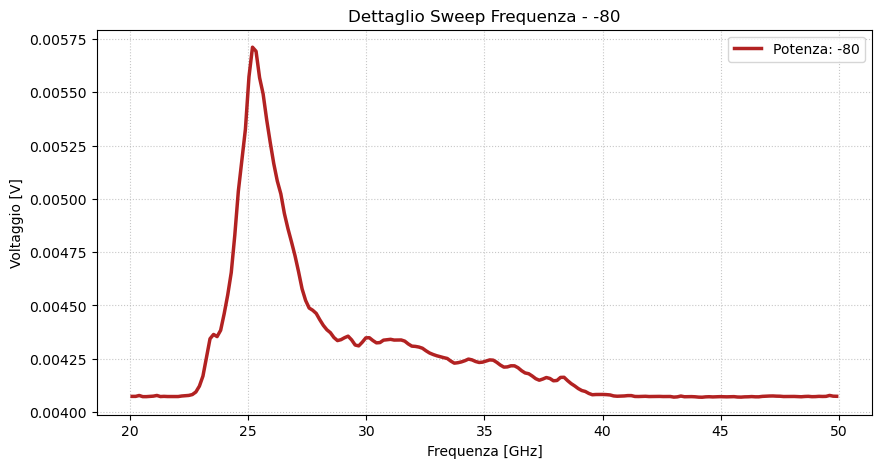

In [2]:
def plot_singola_potenza(risultati, potenza_target):
    if potenza_target in risultati:
        f, m = risultati[potenza_target]
        
        plt.figure(figsize=(10, 5))
        plt.plot(f, m, color='firebrick', linewidth=2.5, label=f"Potenza: {potenza_target}")
        
        plt.title(f"Dettaglio Sweep Frequenza - {potenza_target}")
        plt.xlabel("Frequenza [GHz]")
        plt.ylabel("Voltaggio [V]")
    
        plt.grid(True, which='both', linestyle=':', alpha=0.7)
        plt.legend()
        plt.show()
    else:
        print(f"Errore: La potenza '{potenza_target}' non è presente nei dati.")
        print(f"Potenze disponibili: {list(risultati.keys())}")
        
plot_singola_potenza(risultati_finali, -80)


Ho carico la calibrazione del diodo fatta in precedenza gli hanni scorsi e calcolo la risposta del diodo solamente ottenedo dal voltaggio misurato da noi una serie di curve in potenza poi le confronto con l'uscita del generatore ovvero l'input del nostro sistema assumendo la funzione di risposta del generatore come una tophat

In [3]:
df = pd.read_excel('dati_potenza.xlsx')

#rimuovo la prima riga che non mi serve
df = df.iloc[1:].reset_index(drop=True)

#salvo la colonna della potenza e la frequenza e le rimuovo coì da rimanere
# solo con la matrice dei voltaggi
#powers = df.iloc[1:, 1].values
powers_old = powers_dbm = df.iloc[1:,0].values
df = df.drop(df.columns[:1], axis=1)
freqs_old = df.iloc[0,1:].values
df = df.iloc[1:].reset_index(drop=True)
df = df.drop(df.columns[:1], axis=1)
#voltaggi negativi per diodo negativo e riportati in mv come la calibrazioen del diodo
volts = df.values/1000
volts_old = volts.T

print(freqs_old)
print(powers_old)


[26 27.0 28.0 29.0 30.0 30.5 31.0 32.0 33.0 34.0 35.0 36.0 37.0 38.0 39.0
 40.0]
[-33 -30 -25 -20 -18 -15 -12 -10 -8 -5 -2 0 2 4]


In [4]:
#LOADING NEW DIODE CALIRATION
freqs = np.load('freqs.npy')
powers = np.load('powers.npy')
volts = np.load('volts.npy')

print(freqs)
print(powers)

[20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]
[-33 -30 -27 -25 -23 -20 -18 -15 -13 -10  -8  -5  -3   0   3   5]


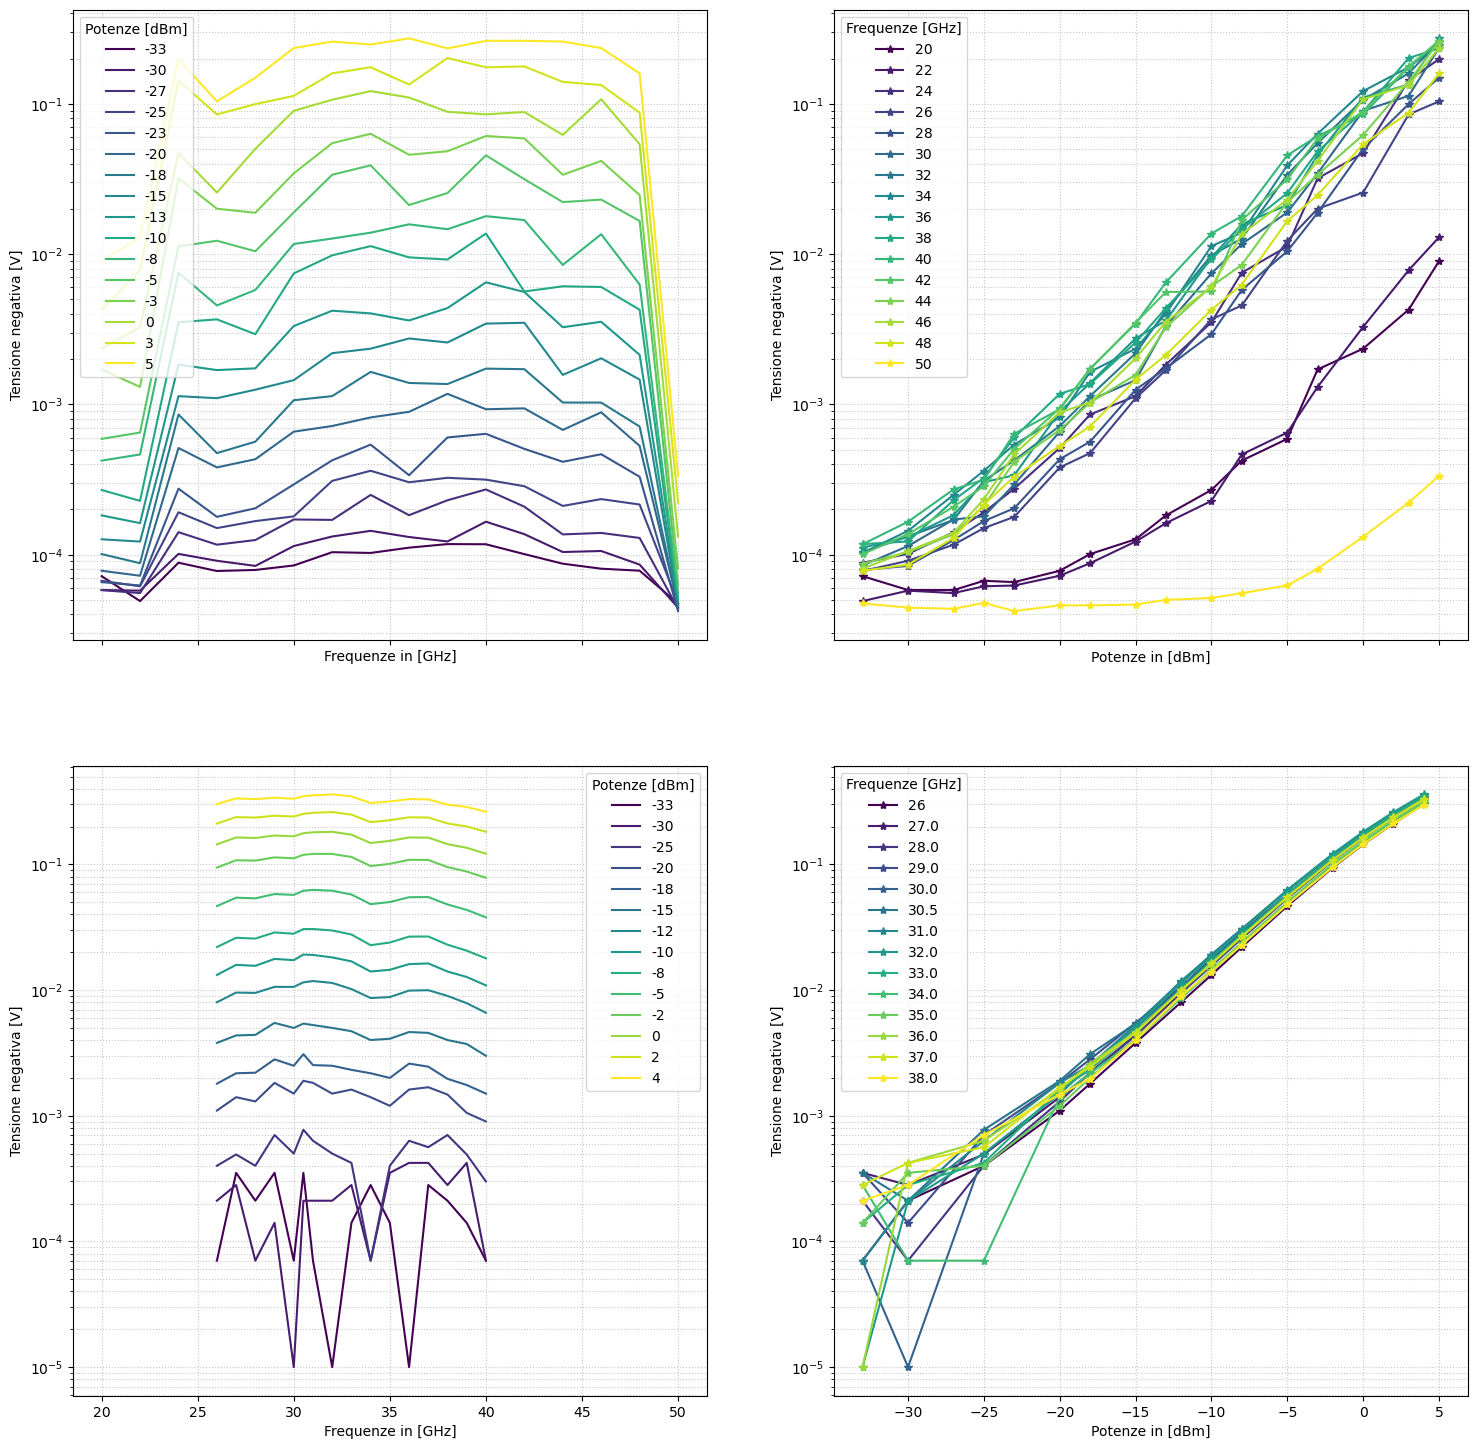

In [5]:
colors_new = plt.cm.viridis(np.linspace(0, 1, len(powers)))
colors_old = plt.cm.viridis(np.linspace(0, 1, len(powers_old)))

fig,((ax11,ax12),(ax21,ax22)) = plt.subplots(2,2,figsize=(18,18), sharex='col')

for (power,volts_power,color) in zip(powers,volts.T,colors_new):
    ax11.semilogy(freqs,volts_power,label=f"{power}",color=color)


for (freq,volts_freq,color) in zip(freqs,volts,colors_new):
    ax12.semilogy(powers,volts_freq,label=f"{freq}",color=color,marker = "*")

for (power,volts_power,color) in zip(powers_old,volts_old.T,colors_old):
    ax21.semilogy(freqs_old,volts_power,label=f"{power}",color=color)


for (freq,volts_freq,color) in zip(freqs_old,volts_old,colors_old):
    ax22.semilogy(powers_old,volts_freq,label=f"{freq}",color=color,marker = "*")

    
ax11.legend(title = "Potenze [dBm]")
ax11.set_xlabel("Frequenze in [GHz]")
ax11.set_ylabel("Tensione negativa [V]")
ax11.grid(True, which='both', linestyle=':', alpha=0.7)


ax12.legend(title = "Frequenze [GHz]")
ax12.set_xlabel("Potenze in [dBm]")
ax12.set_ylabel("Tensione negativa [V]")
ax12.grid(True, which='both', linestyle=':', alpha=0.7)

ax21.legend(title = "Potenze [dBm]")
ax21.set_xlabel("Frequenze in [GHz]")
ax21.set_ylabel("Tensione negativa [V]")
ax21.grid(True, which='both', linestyle=':', alpha=0.7)


ax22.legend(title = "Frequenze [GHz]")
ax22.set_xlabel("Potenze in [dBm]")
ax22.set_ylabel("Tensione negativa [V]")
ax22.grid(True, which='both', linestyle=':', alpha=0.7)

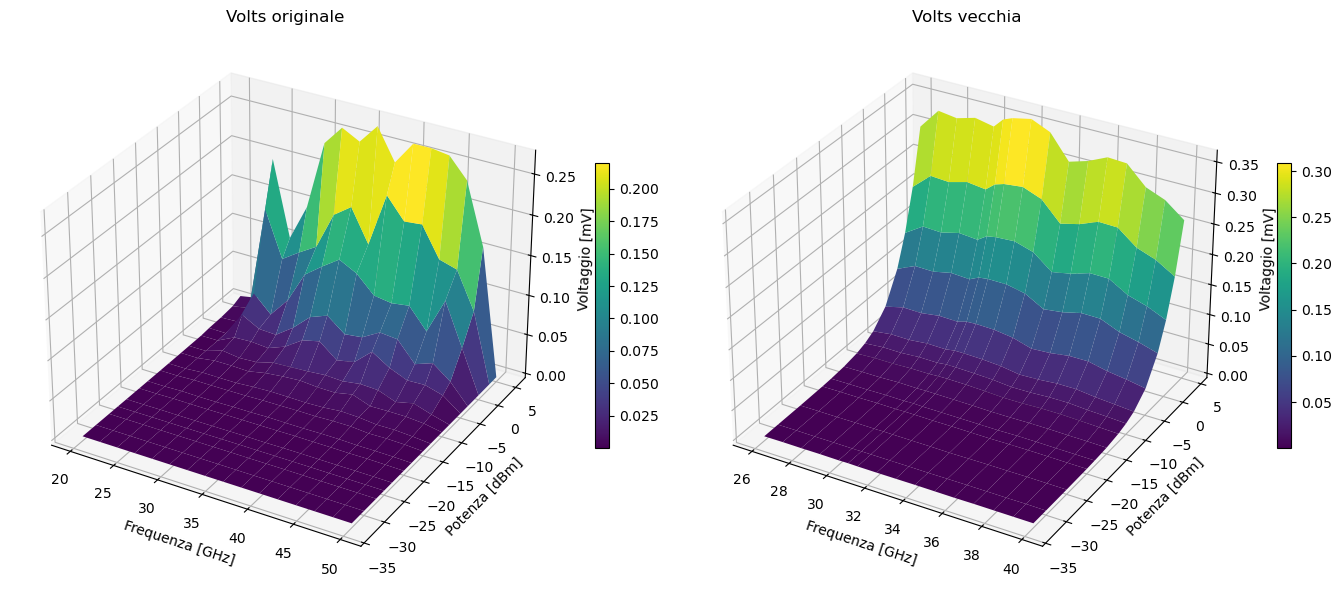

In [9]:

X_grid, Y_grid = np.meshgrid(freqs, powers, indexing='ij')

# reshape alla forma originale della griglia
volts = volts.reshape(X_grid.shape)

fig = plt.figure(figsize=(14, 6))

# --- primo grafico ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(X_grid, Y_grid, volts, cmap='viridis', antialiased=True)

ax1.set_title("Volts originale")
ax1.set_xlabel('Frequenza [GHz]')
ax1.set_ylabel('Potenza [dBm]')
ax1.set_zlabel('Voltaggio [mV]')

fig.colorbar(surf1, ax=ax1, shrink=0.5)

volts_old = np.asarray(volts_old, dtype=float)
volts_old = np.nan_to_num(volts_old.astype(float), nan=0.0)
freqs_old = freqs_old.astype(float)
powers_old = powers_old.astype(float)
X_grid, Y_grid = np.meshgrid(freqs_old, powers_old, indexing='ij')

# --- secondo grafico ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(X_grid, Y_grid, volts_old, cmap='viridis', antialiased=True)

ax2.set_title("Volts vecchia")
ax2.set_xlabel('Frequenza [GHz]')
ax2.set_ylabel('Potenza [dBm]')
ax2.set_zlabel('Voltaggio [mV]')

fig.colorbar(surf2, ax=ax2, shrink=0.5)

plt.tight_layout()
plt.show()

In [37]:
import numpy as np
from scipy.interpolate import interpn, interp1d
def power_interpn(freq_target, volt_target, freqs, powers, volts_matrix,DEBUG=0):
       
    # 1. Definiamo un range di potenze su cui campionare il profilo di tensione
    # Usiamo un numero di punti sufficiente per la precisione dell'inversione
    p_esteso = powers
    
    # 2. STRUTTURA PUNTI: [frequenza, potenza]
    # La frequenza è fissa (freq_target), la potenza varia
    punti_campionamento = np.array([[freq_target, p] for p in p_esteso])
    
    # 3. INTERPN: (freqs, powers) combacia con volts_matrix (F x P)
    # Estraiamo il profilo di tensione lungo l'asse della potenza alla frequenza target
    v_profilo = interpn((freqs, powers), volts_matrix, punti_campionamento, 
                        method='linear', bounds_error=False, fill_value=None)

    # 4. Inversione per trovare la potenza dato un voltaggio
    # Rimuoviamo eventuali non-monotonicità (necessario per interp1d)
    # Nota: unique ordina i valori automaticamente
    v_unico, indici = np.unique(v_profilo, return_index=True)
    p_unico = p_esteso[sorted(indici)]

    if DEBUG:
        plt.ylabel("Tensione [V]")
        plt.xlabel("Potenza [dBm]")
        plt.semilogy(p_unico,v_unico)

        
    f_inversa = interp1d(v_unico, p_unico, kind='linear', fill_value="extrapolate")
    
    return f_inversa(volt_target)

0.004074233333333333


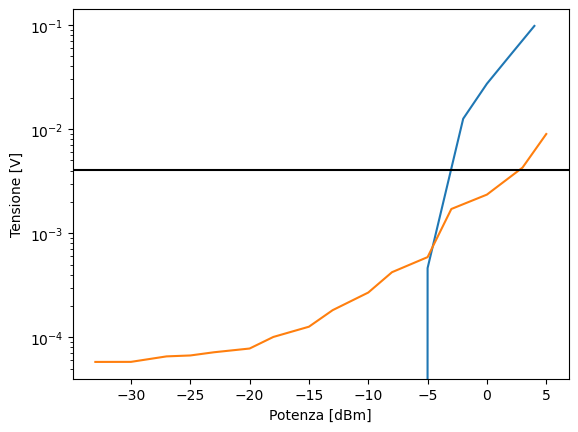

In [47]:
f,v = risultati_finali[-80]
print(v[-1])

f_ = 20

power_interpn(f_,v[-1],freqs_old,powers_old,volts_old,DEBUG=1)
power_interpn(f_,v[-1],freqs,powers,volts,DEBUG=1)


plt.axhline(v[0],c="black")

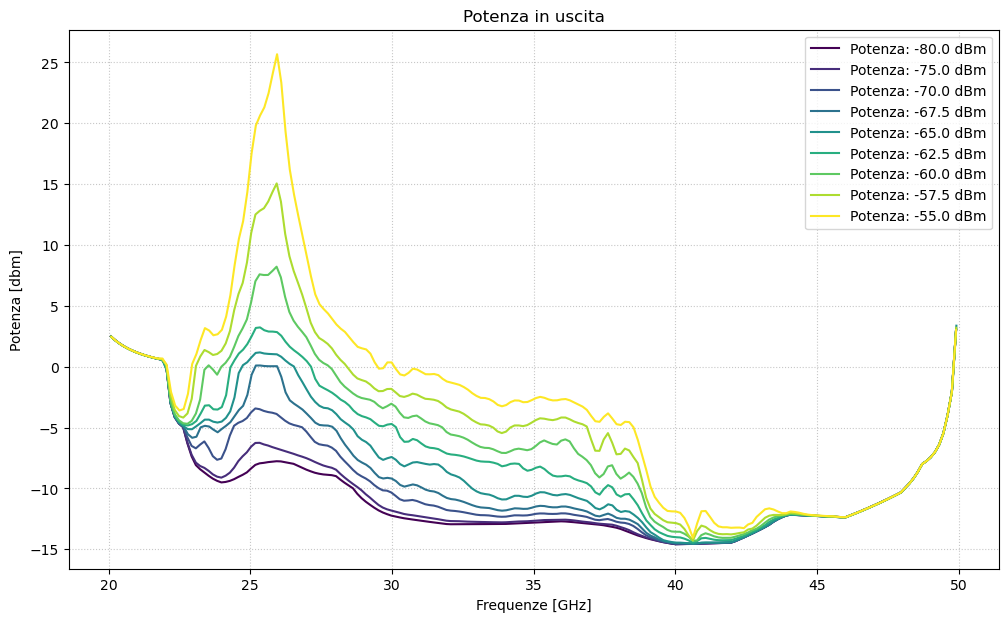

In [42]:
fig, ax = plt.subplots(figsize=(12, 7))

keys = sorted(risultati_finali.keys())

colors = plt.cm.viridis(np.linspace(0, 1, len(keys)))

output_power = []
for (key,color) in zip(keys,colors):
    f,v = risultati_finali[key]
    mag = []
    for i in range(int(len(f))):
        mag.append(power_interpn(f[i],v[i],freqs,powers,volts))

    ax.plot(f,mag,label=f"Potenza: {key} dBm",color=color)
    output_power.append(mag)

ax.set_title("Potenza in uscita")
ax.set_xlabel(f"Frequenze [GHz]")
ax.set_ylabel(f"Potenza [dbm]")
#ax.set_xlim(20,44)
#ax.set_ylim(-20,15)
ax.grid(True, which='both', linestyle=':', alpha=0.7)
ax.legend()

   

In [43]:
print(min(output_power[0]))
output_power[0][0]

-14.581580643736103


array(2.50571414)

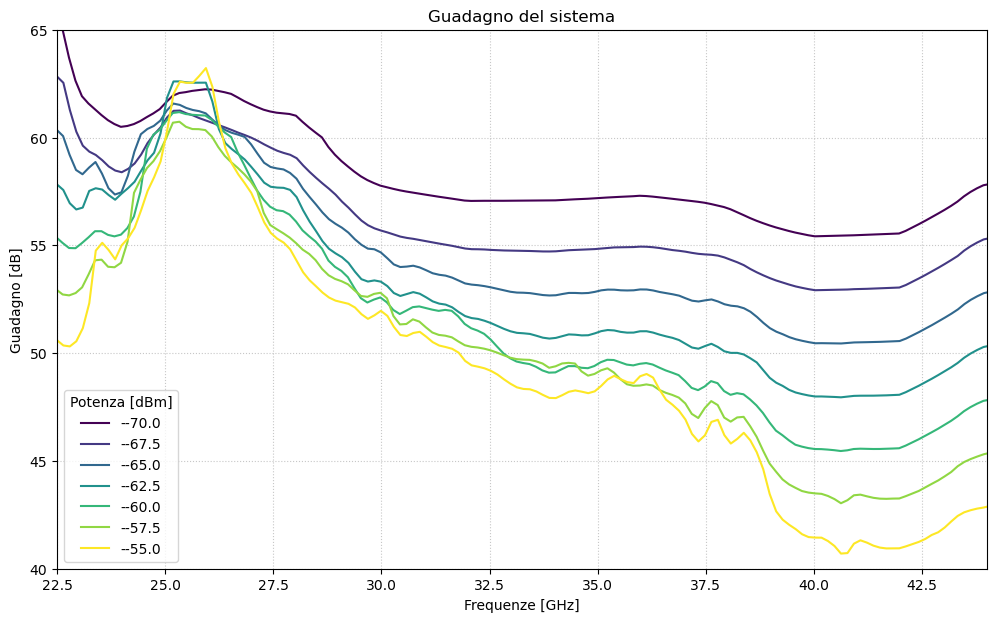

In [52]:
fig, ax = plt.subplots(figsize=(12, 7))

keys = sorted(risultati_finali.keys())[2:]
colors = plt.cm.viridis(np.linspace(0, 1, len(keys)))
i_s = range(len(keys))



for (i,key,color) in zip(i_s,keys,colors):
    f,m = risultati_finali[key]
    powers_i = output_power[i]
    mag=[]
    for j in range(int(len(f))):
        mag.append(powers_i[j]-float(key))
        #mag.append(10*np.log10(10**(powers_i[j]/10)/10**(float(key)/10)))
        
    ax.plot(f,mag,label=f"-{key}",color=color)

ax.set_title("Guadagno del sistema")
ax.set_xlabel(f"Frequenze [GHz]")
ax.set_ylabel(f"Guadagno [dB]")
ax.set_xlim(22.5,44)
ax.set_ylim(40,65)
ax.grid(True, which='both', linestyle=':', alpha=0.7)
ax.legend(title="Potenza [dBm]")